# Parte III, Q4: concentração em consoles

A Q4 do notebook 03 mostrou a homofilia por plataforma. Aqui aprofundamos a pergunta: **qual é o papel dos consoles na rede?**
Usamos só os dados tratados (`data/processado/`), então este notebook roda sem os arquivos brutos.

Os metadados têm dois níveis de rótulo, `plataforma` e `tipo`, e eles não são homogêneos: em *Retro Gaming & Microconsoles* e em *Kids & Family* o console aparece no `tipo`. O módulo `src/parte3/consoles.py` normaliza os dois níveis em:
- **classe de produto:** console, acessório, jogo, retrô, outros (figuras, cartões, VR) e sem rótulo;
- **família de console:** Wii, PlayStation 4, PC etc., com o mesmo nome nos dois níveis.

Ressalva: uma aresta é **coavaliação**, não compra. A avaliação é um sinal de que o usuário teve contato com o produto, e o CSV de 2018 não informa se a compra foi verificada.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import math
from collections import Counter
from IPython.display import Markdown, display

from src.comum import config
from src.comum.carga import carregar_grafo_analise
from src.comum.exportacao import escrever_tabela, formatar_markdown
from src.comum.validacao import calcular_intermediacao
from src.comum.visualizacao import salvar_figura
from src.parte3.consoles import (
    CLASSES, CONSOLE, DESCONHECIDA, calcular_assortatividade, calcular_gini, calcular_mistura,
    classificar_produto, contar_arestas_entre_consoles, familia_de_console,
    medir_cobertura_dos_consoles, medir_participacao, permutar_rotulos_homofilia,
)
from src.parte3.robustez import calcular_r, ordenar_por_centralidade

DIR_RESULTADOS, DIR_IMAGENS = config.RAIZ / "results", config.RAIZ / "imagens"
DIR_RESULTADOS.mkdir(exist_ok=True)
grafo = carregar_grafo_analise(config.DIR_PROCESSADO)
classes = {v: classificar_produto(j) for v, j in grafo.jogos.items()}
familias = {v: familia_de_console(j) for v, j in grafo.jogos.items()}
graus = {v: len(viz) for v, viz in grafo.adjacencia.items()}
forca = Counter()
for (p, q), w in grafo.pesos.items():
    forca[p] += w
    forca[q] += w
resumo = []  # (medida, valor) para results/parte3_consoles_resumo.csv
print(f"LCC: {len(graus):,} vértices, {len(grafo.pesos):,} arestas")

LCC: 21,284 vértices, 320,742 arestas


## 1. Quanto cada classe concentra

Para cada classe: fração dos vértices, fração das pontas de aresta (soma dos graus) e fração da força (soma dos pesos).
Se uma classe tem mais pontas do que vértices, seus produtos são, em média, mais conectados que o resto.

In [2]:
participacao = medir_participacao(grafo.pesos, classes)
linhas = [[p.classe, p.vertices, f"{p.fracao_vertices:.2%}", f"{p.fracao_pontas:.2%}", f"{p.fracao_forca:.2%}",
           f"{p.grau_medio:.1f}", f"{p.fracao_pontas / p.fracao_vertices:.2f}"] for p in participacao]
cabecalho = ["classe", "vértices", "% vértices", "% pontas", "% força", "grau médio", "pontas / vértices"]
display(Markdown(formatar_markdown(cabecalho, linhas)))
with open(DIR_RESULTADOS / "parte3_consoles_participacao.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, linhas, fluxo)
console = next(p for p in participacao if p.classe == CONSOLE)
resumo += [("consoles", console.vertices), ("consoles_fracao_vertices", console.fracao_vertices),
           ("consoles_fracao_pontas", console.fracao_pontas), ("consoles_grau_medio", console.grau_medio),
           ("grau_medio_lcc", 2 * len(grafo.pesos) / len(graus))]

| classe | vértices | % vértices | % pontas | % força | grau médio | pontas / vértices |
|---|---|---|---|---|---|---|
| jogo | 10556 | 49.60% | 56.87% | 57.41% | 34.6 | 1.15 |
| retrô | 4702 | 22.09% | 14.33% | 12.78% | 19.6 | 0.65 |
| acessório | 4417 | 20.75% | 17.30% | 17.66% | 25.1 | 0.83 |
| sem rótulo | 908 | 4.27% | 6.21% | 6.49% | 43.9 | 1.46 |
| outros | 411 | 1.93% | 2.40% | 2.67% | 37.4 | 1.24 |
| console | 290 | 1.36% | 2.90% | 2.99% | 64.1 | 2.13 |

## 2. Com quem cada classe se liga

Matriz de mistura de Newman (2003): $e_{ab}$ é a fração das pontas que ligam as classes $a$ e $b$, e $a_a = \sum_b e_{ab}$.
A razão $e_{ab}/(a_a a_b)$ compara o observado com o esperado se as pontas se ligassem ao acaso: acima de 1, as classes se procuram; abaixo de 1, se evitam.

In [3]:
e, a = calcular_mistura(grafo.pesos, classes)
ordem = [c for c in CLASSES if c in a]
razoes = {(x, y): e.get((x, y), 0.0) / (a[x] * a[y]) for x in ordem for y in ordem}
linhas = [[x, *[f"{razoes[(x, y)]:.2f}" for y in ordem]] for x in ordem]
display(Markdown(formatar_markdown(["classe", *ordem], linhas)))
with open(DIR_RESULTADOS / "parte3_consoles_mistura.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["classe", *ordem], linhas, fluxo)
for par in [("console", "console"), ("console", "acessório"), ("console", "jogo"), ("acessório", "acessório"), ("jogo", "jogo")]:
    resumo.append((f"mistura_{par[0]}_{par[1]}", razoes[par]))

| classe | console | acessório | jogo | retrô | outros | sem rótulo |
|---|---|---|---|---|---|---|
| console | 2.83 | 1.23 | 1.01 | 0.32 | 0.63 | 1.12 |
| acessório | 1.23 | 2.68 | 0.65 | 0.24 | 0.88 | 1.21 |
| jogo | 1.01 | 0.65 | 1.31 | 0.28 | 0.53 | 1.01 |
| retrô | 0.32 | 0.24 | 0.28 | 5.31 | 0.12 | 0.46 |
| outros | 0.63 | 0.88 | 0.53 | 0.12 | 18.74 | 1.02 |
| sem rótulo | 1.12 | 1.21 | 1.01 | 0.46 | 1.02 | 1.47 |

## 3. Homofilia por família de console

A Q4 do notebook 03 mediu a homofilia com o rótulo bruto de `plataforma`. Com a família normalizada, *Retro* e *Kids & Family* deixam de ser "plataformas" e passam a contar no console certo.
Além da fração observada contra a esperada, calculamos a assortatividade categórica $r$ e um **teste de permutação**: os rótulos são embaralhados entre os vértices (mesma topologia, mesma quantidade de cada rótulo) 1.000 vezes.

In [4]:
plataformas = {v: j.plataforma for v, j in grafo.jogos.items()}
linhas = []
for nome, rotulos in [("plataforma (bruta)", plataformas), ("família (normalizada)", familias), ("classe de produto", classes)]:
    e_r, a_r = calcular_mistura(grafo.pesos, rotulos)
    dentro, acaso = sum(e_r.get((x, x), 0) for x in a_r), sum(v * v for v in a_r.values())
    teste = permutar_rotulos_homofilia(grafo.pesos, rotulos, 1000, config.SEED)
    linhas.append([nome, len(a_r), f"{teste.observada:.1%}", f"{acaso:.1%}", f"{teste.observada / acaso:.1f}",
                   f"{calcular_assortatividade(grafo.pesos, rotulos):.3f}",
                   f"{calcular_assortatividade(grafo.pesos, rotulos, ponderada=True):.3f}",
                   f"{teste.media_nula:.1%} ± {teste.dp_nulo:.1%}", f"{teste.maior_nula:.1%}"])
    chave = nome.split()[0]
    resumo += [(f"homofilia_{chave}_observada", teste.observada), (f"homofilia_{chave}_esperada", acaso),
               (f"homofilia_{chave}_r", calcular_assortatividade(grafo.pesos, rotulos)),
               (f"homofilia_{chave}_r_ponderado", calcular_assortatividade(grafo.pesos, rotulos, ponderada=True)),
               (f"homofilia_{chave}_nulo_media", teste.media_nula), (f"homofilia_{chave}_nulo_dp", teste.dp_nulo),
               (f"homofilia_{chave}_nulo_max", teste.maior_nula)]
cabecalho = ["rótulo", "valores", "mesma ponta", "esperado", "razão", "r", "r ponderado", "nulo: média ± DP", "nulo: máximo"]
display(Markdown(formatar_markdown(cabecalho, linhas)))
with open(DIR_RESULTADOS / "parte3_consoles_homofilia.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, linhas, fluxo)

| rótulo | valores | mesma ponta | esperado | razão | r | r ponderado | nulo: média ± DP | nulo: máximo |
|---|---|---|---|---|---|---|---|---|
| plataforma (bruta) | 18 | 52.4% | 11.5% | 4.5 | 0.462 | 0.537 | 15.3% ± 0.3% | 16.4% |
| família (normalizada) | 40 | 55.2% | 9.7% | 5.7 | 0.504 | 0.591 | 10.6% ± 0.3% | 11.6% |
| classe de produto | 6 | 63.0% | 37.9% | 1.7 | 0.405 | 0.443 | 34.0% ± 0.6% | 36.0% |

## 4. Os consoles entre si: concentração e rivalidade

- **Concentração:** Gini da força dos consoles e participação dos 5 maiores.
- **Arestas console–console:** quando dois consoles têm avaliadores em comum, são da mesma família (modelos e pacotes do mesmo aparelho) ou de famílias diferentes (o usuário tem mais de um console)?

In [5]:
consoles = [v for v, c in classes.items() if c == CONSOLE]
forca_consoles = sorted((forca[v] for v in consoles), reverse=True)
gini_consoles, gini_lcc = calcular_gini(forca_consoles), calcular_gini(list(forca.values()))
top5 = sum(forca_consoles[:5]) / sum(forca_consoles)
print(f"Gini da força: consoles {gini_consoles:.3f}, LCC inteira {gini_lcc:.3f}; 5 maiores consoles = {top5:.1%} da força dos consoles")
posicao = {v: i + 1 for i, v in enumerate(ordenar_por_centralidade(graus))}
linhas = [[posicao[v], graus[v], forca[v], familias[v], grafo.jogos[v].titulo[:55]]
          for v in sorted(consoles, key=lambda v: -forca[v])[:10]]
display(Markdown("**Consoles com maior força**\n\n" + formatar_markdown(["posição por grau", "grau", "força", "família", "título"], linhas)))

pares = contar_arestas_entre_consoles(grafo.pesos, classes, familias)
total = sum(pares.values())
mesma = sum(w for (x, y), w in pares.items() if x == y)
print(f"peso console–console: {total:,}; mesma família {mesma / total:.1%}, famílias diferentes {1 - mesma / total:.1%}")
cruzados = [[x, y, w, f"{w / total:.1%}"] for (x, y), w in pares.most_common() if x != y][:8]
display(Markdown("**Pares de famílias diferentes com mais peso**\n\n" + formatar_markdown(["família", "família", "peso", "% console–console"], cruzados)))
with open(DIR_RESULTADOS / "parte3_consoles_pares.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["familia_a", "familia_b", "peso"], [[x, y, w] for (x, y), w in pares.most_common()], fluxo)
resumo += [("gini_forca_consoles", gini_consoles), ("gini_forca_lcc", gini_lcc), ("top5_consoles_fracao_forca", top5),
           ("console_console_peso", total), ("console_console_mesma_familia", mesma / total)]
resumo += [(f"par_{x}_{y}", w) for x, y, w, _ in cruzados[:3]]

Gini da força: consoles 0.762, LCC inteira 0.820; 5 maiores consoles = 24.5% da força dos consoles


**Consoles com maior força**

| posição por grau | grau | força | família | título |
|---|---|---|---|---|
| 35 | 788 | 3424 | PlayStation 4 | PlayStation 4 500GB Console [Old Model][Discontinued] |
| 66 | 659 | 3240 | Xbox One | Xbox One + Kinect |
| 40 | 757 | 3239 | Xbox 360 | Gears of War 3 |
| 24 | 843 | 3062 | Nintendo DS | Nintendo DS Lite Polar White |
| 94 | 596 | 2658 | Xbox One | Xbox One 500GB Console - Assassin's Creed Unity Bundle |
| 99 | 572 | 2237 | Nintendo 3DS | Fire Emblem: Awakening |
| 108 | 548 | 2040 | Nintendo 3DS | The Legend of Zelda: Majora's Mask 3D |
| 161 | 464 | 1733 | Wii U | Nintendo Wii U Console - 32GB Black Deluxe Set |
| 206 | 413 | 1641 | Nintendo 3DS | Nintendo New 3DS XL - Black |
| 306 | 334 | 1212 | PlayStation Vita | Sony PlayStation Vita WiFi |

peso console–console: 2,521; mesma família 54.1%, famílias diferentes 45.9%


**Pares de famílias diferentes com mais peso**

| família | família | peso | % console–console |
|---|---|---|---|
| PlayStation 4 | Xbox One | 134 | 5.3% |
| Xbox 360 | Xbox One | 119 | 4.7% |
| Nintendo DS | Sony PSP | 68 | 2.7% |
| PlayStation 3 | Xbox 360 | 60 | 2.4% |
| Nintendo DS | PlayStation 3 | 58 | 2.3% |
| Nintendo 3DS | Nintendo DS | 57 | 2.3% |
| Wii U | Xbox One | 52 | 2.1% |
| Nintendo 3DS | Xbox One | 50 | 2.0% |

## 5. Quanto do catálogo está a uma aresta do console

Para cada família, a fração dos seus produtos (fora os próprios consoles) vizinha de ao menos um console da mesma família.

In [6]:
cobertura = medir_cobertura_dos_consoles(grafo.adjacencia, classes, familias)
linhas = [[c.familia, c.consoles, c.produtos, c.cobertos, f"{c.fracao_coberta:.1%}"] for c in cobertura]
display(Markdown(formatar_markdown(["família", "consoles", "produtos", "vizinhos de um console", "cobertura"], linhas)))
with open(DIR_RESULTADOS / "parte3_consoles_cobertura.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["familia", "consoles", "produtos", "cobertos", "fracao"], [[c.familia, c.consoles, c.produtos, c.cobertos, round(c.fracao_coberta, 4)] for c in cobertura], fluxo)
resumo += [("cobertura_max", cobertura[0].fracao_coberta), ("cobertura_max_familia", cobertura[0].familia),
           ("cobertura_min", cobertura[-1].fracao_coberta), ("cobertura_min_familia", cobertura[-1].familia)]

| família | consoles | produtos | vizinhos de um console | cobertura |
|---|---|---|---|---|
| PlayStation Vita | 20 | 299 | 162 | 54.2% |
| Xbox One | 38 | 952 | 368 | 38.7% |
| Nintendo 3DS | 52 | 723 | 279 | 38.6% |
| Wii U | 13 | 318 | 113 | 35.5% |
| Nintendo DS | 18 | 1095 | 358 | 32.7% |
| Xbox 360 | 60 | 1856 | 602 | 32.4% |
| Sony PSP | 22 | 499 | 157 | 31.5% |
| PlayStation 4 | 25 | 1134 | 352 | 31.0% |
| PlayStation 3 | 29 | 1604 | 310 | 19.3% |
| Wii | 13 | 1380 | 56 | 4.1% |

## 6. Os hubs e as pontes são consoles?

Comparamos a fração de consoles entre os $r = \lceil 0{,}05n \rceil$ vértices do topo de cada ranking (os mesmos removidos no ataque da Q3) com a fração de consoles na LCC.

In [7]:
r = calcular_r(len(graus))
intermediacao = calcular_intermediacao(grafo.adjacencia)
linhas = []
for nome, centralidade in [("grau", graus), ("betweenness", intermediacao)]:
    ranking = ordenar_por_centralidade(centralidade)
    topo = Counter(classes[v] for v in ranking[:r])
    linhas.append([nome, topo[CONSOLE], f"{topo[CONSOLE] / r:.1%}", f"{topo[CONSOLE] / r / console.fracao_vertices:.1f}",
                   Counter(classes[v] for v in ranking[:20])[CONSOLE]])
    resumo += [(f"topo_r_{nome}_consoles", topo[CONSOLE]), (f"topo_r_{nome}_fracao_consoles", topo[CONSOLE] / r),
               (f"topo20_{nome}_consoles", Counter(classes[v] for v in ranking[:20])[CONSOLE])]
display(Markdown(formatar_markdown(["ranking", "consoles no topo r", "% do topo", "vezes a fração na LCC", "consoles no top 20"], linhas)))
mais_central = ordenar_por_centralidade(intermediacao)[0]
print(f"maior betweenness: {grafo.jogos[mais_central].titulo} (classe: {classes[mais_central]}, tipo bruto: {grafo.jogos[mais_central].tipo!r})")
with open(DIR_RESULTADOS / "parte3_consoles_resumo.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["medida", "valor"], [[k, round(v, 6) if isinstance(v, float) else v] for k, v in resumo], fluxo)

| ranking | consoles no topo r | % do topo | vezes a fração na LCC | consoles no top 20 |
|---|---|---|---|---|
| grau | 39 | 3.7% | 2.7 | 0 |
| betweenness | 26 | 2.4% | 1.8 | 1 |

maior betweenness: Wii (classe: sem rótulo, tipo bruto: 'desconhecida')


## 7. Visualização reduzida: as panelas por família

Com 21 mil vértices e 320 mil arestas, o desenho da LCC inteira vira um borrão. Fazemos duas reduções, ambas com as funções de `src/parte3/consoles.py`:

1. **Grafo entre famílias:** um vértice por família de console com ao menos 100 produtos, do tamanho do seu catálogo e com a cor do fabricante. Cada família se liga às **duas** famílias com que mais se mistura acima do acaso, pela razão $e_{ab}/(a_a a_b)$ da seção 2. A espessura da aresta cresce com essa razão.
2. **Subgrafo das panelas:** os 30 produtos de maior força de cada uma das 12 maiores famílias (360 vértices). De cada produto, mantemos só as **3 arestas mais pesadas** dentro da seleção. A redução não favorece arestas dentro da família: se elas dominam o desenho, é porque dominam os vizinhos mais fortes. Para conferir que isso não é efeito da seleção, medimos a mesma fração na rede inteira.

**Ligações mais fortes entre famílias** (razão observado / esperado)

| família | família | razão | mesmo fabricante? |
|---|---|---|---|
| Nintendo NES | Super Nintendo | 24.9 | sim |
| Game Boy Advance | Game Boy Color | 20.4 | sim |
| Nintendo NES | Sega Genesis | 17.3 | não |
| Sega Genesis | Super Nintendo | 16.5 | não |
| Game Boy Color | Nintendo 64 | 8.7 | sim |
| Nintendo 64 | Super Nintendo | 8.1 | sim |
| Game Boy Advance | GameCube | 6.8 | sim |
| Sega Dreamcast | Sega Genesis | 6.3 | sim |

grafo entre famílias: 23 famílias, 30 ligações, 20 entre famílias do mesmo fabricante


subgrafo reduzido: 360 vértices, 838 arestas, 83.1% dentro da família
rede inteira, 3 arestas mais pesadas de cada produto: 46,275 arestas, 76.0% dentro da família (todas as arestas: 55.2%)


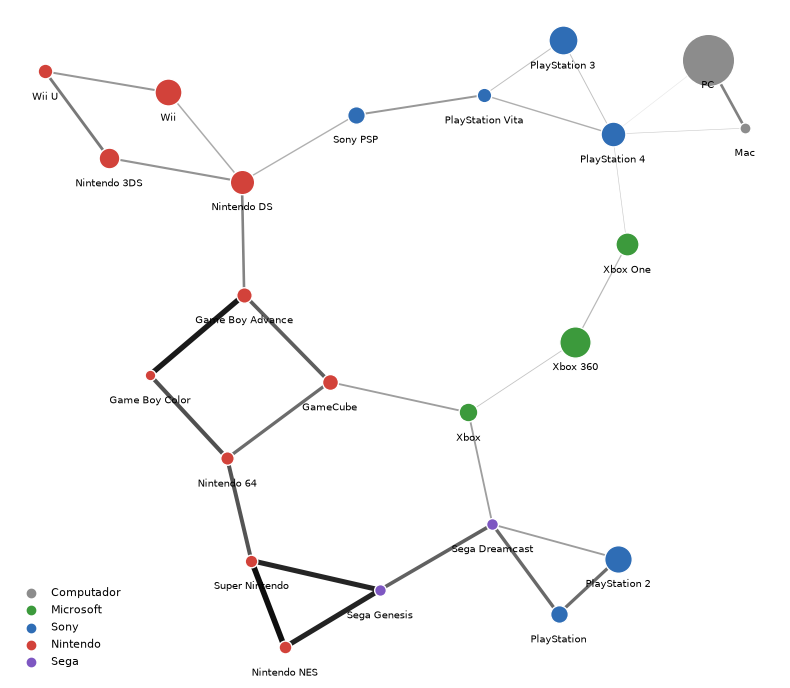

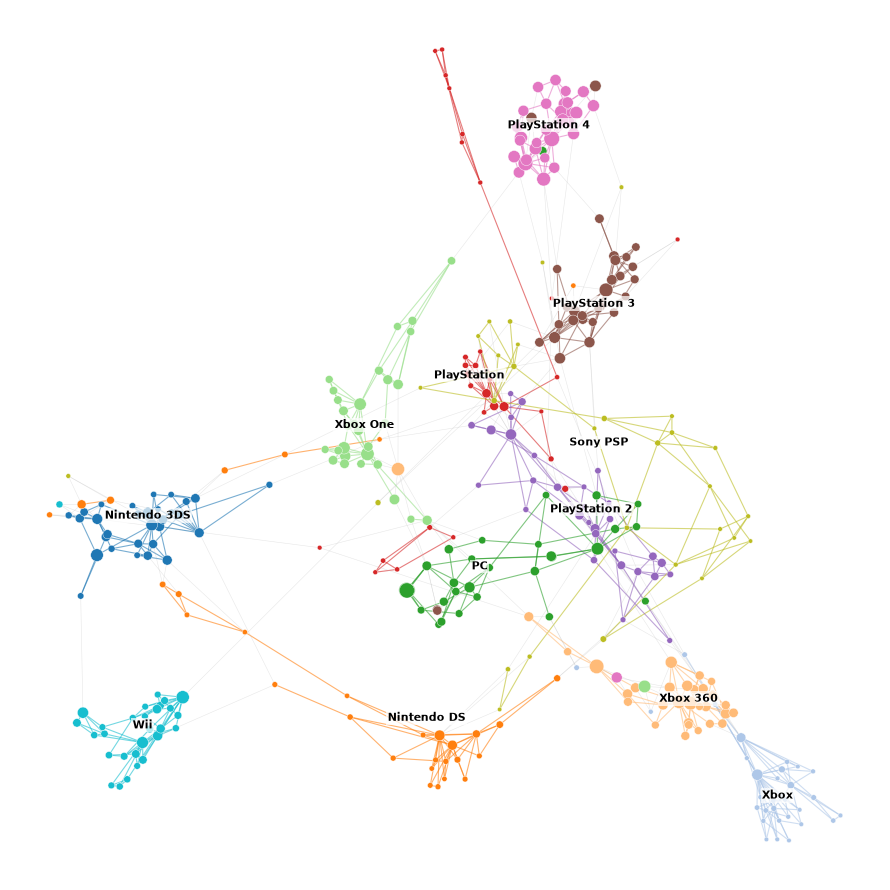

In [8]:
from src.comum.visualizacao import desenhar_mapa_de_familias, desenhar_panelas
from src.parte3.consoles import identificar_fabricante, ligar_parceiros_mais_fortes, reduzir_para_panelas

tamanho_familia = Counter(familias.values())
grandes = [f for f, q in tamanho_familia.most_common() if q >= 100 and f != DESCONHECIDA]
ligacoes = ligar_parceiros_mais_fortes(grafo.pesos, familias, grandes, k=2)
figura = desenhar_mapa_de_familias(ligacoes, {f: tamanho_familia[f] for f in grandes},
                                   {f: identificar_fabricante(f) for f in grandes})
salvar_figura(figura, DIR_IMAGENS / "parte3_mapa_familias")
mais_fortes = sorted(ligacoes.items(), key=lambda item: -item[1])[:8]
display(Markdown("**Ligações mais fortes entre famílias** (razão observado / esperado)\n\n" + formatar_markdown(
    ["família", "família", "razão", "mesmo fabricante?"],
    [[a, b, f"{r:.1f}", "sim" if identificar_fabricante(a) == identificar_fabricante(b) else "não"] for (a, b), r in mais_fortes])))
mesmo_fabricante = sum(identificar_fabricante(a) == identificar_fabricante(b) for a, b in ligacoes)
print(f"grafo entre famílias: {len(grandes)} famílias, {len(ligacoes)} ligações, {mesmo_fabricante} entre famílias do mesmo fabricante")

panelas = reduzir_para_panelas(grafo.pesos, familias, grandes[:12], por_rotulo=30, k=3)
figura = desenhar_panelas(panelas, familias, forca, config.SEED)
salvar_figura(figura, DIR_IMAGENS / "parte3_panelas")
dentro_reduzido = sum(familias[p] == familias[q] for p, q in panelas) / len(panelas)

vizinhos_fortes = {}
for (p, q), w in grafo.pesos.items():
    for v, u in ((p, q), (q, p)):
        vizinhos_fortes.setdefault(v, []).append((w, u))
top3 = {tuple(sorted((v, u))) for v, lista in vizinhos_fortes.items() for _, u in sorted(lista, reverse=True)[:3]}
dentro_top3 = sum(familias[p] == familias[q] for p, q in top3) / len(top3)
print(f"subgrafo reduzido: {len({v for a in panelas for v in a})} vértices, {len(panelas)} arestas, {dentro_reduzido:.1%} dentro da família")
print(f"rede inteira, 3 arestas mais pesadas de cada produto: {len(top3):,} arestas, {dentro_top3:.1%} dentro da família "
      f"(todas as arestas: {next(v for k, v in resumo if k == 'homofilia_família_observada'):.1%})")
resumo += [("panelas_fracao_dentro", dentro_reduzido), ("top3_fracao_dentro_lcc", dentro_top3),
           ("mapa_ligacoes", len(ligacoes)), ("mapa_ligacoes_mesmo_fabricante", mesmo_fabricante)]
with open(DIR_RESULTADOS / "parte3_consoles_resumo.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["medida", "valor"], [[k, round(v, 6) if isinstance(v, float) else v] for k, v in resumo], fluxo)

## Resposta: o que os consoles mostram

1. **Os consoles são poucos, mas concentram ligações.** São 290 produtos (1,4% da LCC) e respondem por 2,9% das pontas de aresta: o dobro do que sua fração prevê. O grau médio é 64, contra 30 na LCC.
2. **Hardware se liga a hardware.** Console–console aparece 2,8 vezes mais que o acaso, console–acessório 1,2 vez, e console–jogo fica no acaso (1,0). Acessório–acessório também é 2,7 vezes o acaso. Quem avalia um console avalia outros aparelhos e periféricos, mas não mais jogos do que o esperado.
3. **Quase metade das ligações entre consoles cruza famílias.** Do peso console–console, 54% fica na mesma família (modelos e pacotes do mesmo aparelho) e 46% liga famílias diferentes. Os maiores pares cruzados são PS4–Xbox One, os rivais da mesma geração, e Xbox 360–Xbox One, a troca de geração na mesma marca. Depois vem DS–PSP, os portáteis rivais.
4. **A força dos consoles é desigual, mas menos que a da rede.** O Gini da força é 0,76 entre os consoles (0,82 na LCC inteira). Os 5 maiores (PS4 500GB, Xbox One + Kinect, o pacote do Xbox 360 com Gears of War 3, DS Lite e o pacote do Xbox One com Assassin's Creed Unity) somam 24,5% da força dos consoles. A categoria *Consoles* da Amazon inclui pacotes: por isso aparecem títulos como Fire Emblem: Awakening, que é um 3DS XL com o jogo.
5. **A homofilia por família é mais forte que por plataforma.** Com o rótulo normalizado, a fração de arestas na mesma família vai de 52,4% para 55,2%, contra 9,7% esperados (5,7 vezes), e a assortatividade passa de 0,46 para 0,50 (0,59 ponderada). Nenhuma das 1.000 permutações passa de 11,6%, então $p < 0{,}001$.
6. **Os consoles não são os hubs.** Nenhum console está entre os 20 maiores graus, e eles são só 3,7% do topo $r$ por grau e 2,4% por betweenness. A maior ponte de toda a rede é o próprio Wii, mas ele está sem `tipo` nos metadados e cai em "sem rótulo": a classe *console* é um limite inferior.
7. **A cobertura do catálogo varia muito.** De 54% dos produtos do PS Vita vizinhos de um console Vita a 4% no Wii, cujo console principal está sem rótulo.

**Duas referências, dois nulos.** O "esperado" analítico, $\sum_a a_a^2$, preserva quantas pontas cada rótulo tem. A permutação preserva quantos *vértices* cada rótulo tem. Os dois dão valores diferentes (11,5% e 15,3% na plataforma bruta) porque rótulos com vértices de grau alto pesam mais no primeiro. O observado fica muito acima dos dois.